# Distribution and scatter plots of all factors

This notebook adds two figures to the descriptive analysis of notebook 6:

1. A **boxplot** of charging point density, which shows the distribution and makes outliers visible.
2. **Scatter plots** of charging point density against each explanatory variable, with a least-squares regression line.

The choice of plot follows the data relationship we want to show: a boxplot for a **distribution** with outliers, and scatter plots for the **correlation** between two numerical variables.

**Input:** `data/processed/all_variables_per_municipality.csv`, created by notebook 6. Run notebook 6 first.

**Outputs:** `figures/figure_boxplot_charging_point_density.png`, `figures/figure_scatter_all_factors.png`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PROCESSED = "../data/processed/"
FIGURES = "../figures/"

## 1. Load the data

We use the merged table of notebook 6 and the same readable English labels.

In [2]:
df = pd.read_csv(PROCESSED + "all_variables_per_municipality.csv")

LABELS = {
    "laadpunten_per_1000_huishoudens": "Charging points per 1,000 households",
    "gem_gestandaardiseerd_inkomen_keur": "Mean standardised income (k€)",
    "med_gestandaardiseerd_inkomen_keur": "Median standardised income (k€)",
    "jongeren_onder_25_pct": "Residents under 25 (%)",
    "ouderen_65plus_pct": "Residents 65+ (%)",
    "linkse_stemmen_pct": "Left-wing vote share (%)",
    "linkse_stemmen_smal_pct": "Left-wing vote share, narrow (%)",
    "hoogopgeleid_pct": "Highly educated (%)",
    "bevolkingsdichtheid": "Population density (inh./km²)",
    "meergezinswoning_pct": "Apartments (% of dwellings)",
}
data = df[list(LABELS)].rename(columns=LABELS)
target = "Charging points per 1,000 households"

print("Municipalities:", len(data))

Municipalities: 342


## 2. Boxplot of charging point density

The box runs from the first quartile (Q1) to the third quartile (Q3); the line in the box is the median. Values more than 1.5 × the interquartile range (IQR = Q3 − Q1) above Q3 or below Q1 are outliers and are shown as separate points.

First we calculate the quartiles and find the outliers.

In [3]:
y = data[target]

q1 = y.quantile(0.25)
q3 = y.quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr

print("Q1:", round(q1, 1))
print("Median:", round(y.median(), 1))
print("Q3:", round(q3, 1))
print("Upper fence:", round(upper_fence, 1))

outliers = df[(y > upper_fence) | (y < lower_fence)]
outliers[["gemeente", "laadpunten_per_1000_huishoudens"]].round(1)

Q1: 9.9
Median: 13.5
Q3: 19.3
Upper fence: 33.4


,gemeente,laadpunten_per_1000_huishoudens
148,Katwijk,33.5
169,Loon op Zand,42.9


Then we draw the boxplot and write the name of each outlier above its point.

/var/folders/5l/f73_yvzx7x78mwq61h6pghqw0000gn/T/ipykernel_69126/3731896557.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(y, vert=False)


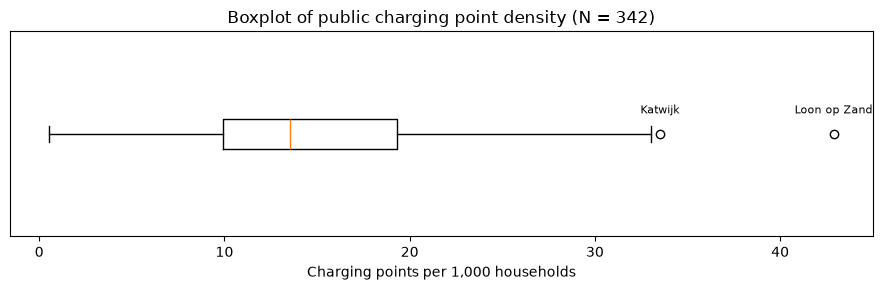

In [4]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(y, vert=False)

for i in outliers.index:
    ax.text(y[i], 1.1, df.loc[i, "gemeente"], ha="center", fontsize=8)

ax.set_yticks([])
ax.set_xlabel("Charging points per 1,000 households")
ax.set_title("Boxplot of public charging point density (N = " + str(len(y)) + ")")
plt.tight_layout()
plt.savefig(FIGURES + "figure_boxplot_charging_point_density.png", dpi=200)
plt.show()

## 3. Scatter plots of all factors

Each panel shows charging point density against one explanatory variable. The red line is the least-squares line y = a + b·x, calculated with `np.polyfit` (see lecture *Data Analysis*). The Pearson correlation r and the number of municipalities N are in the title.

Population density is strongly right-skewed. We therefore plot it on a logarithmic axis and fit the line on log(density), as in the regression (notebook 7).

In [5]:
explanatory = []
for col in data.columns:
    if col != target:
        explanatory.append(col)

print(len(explanatory), "explanatory variables")

9 explanatory variables


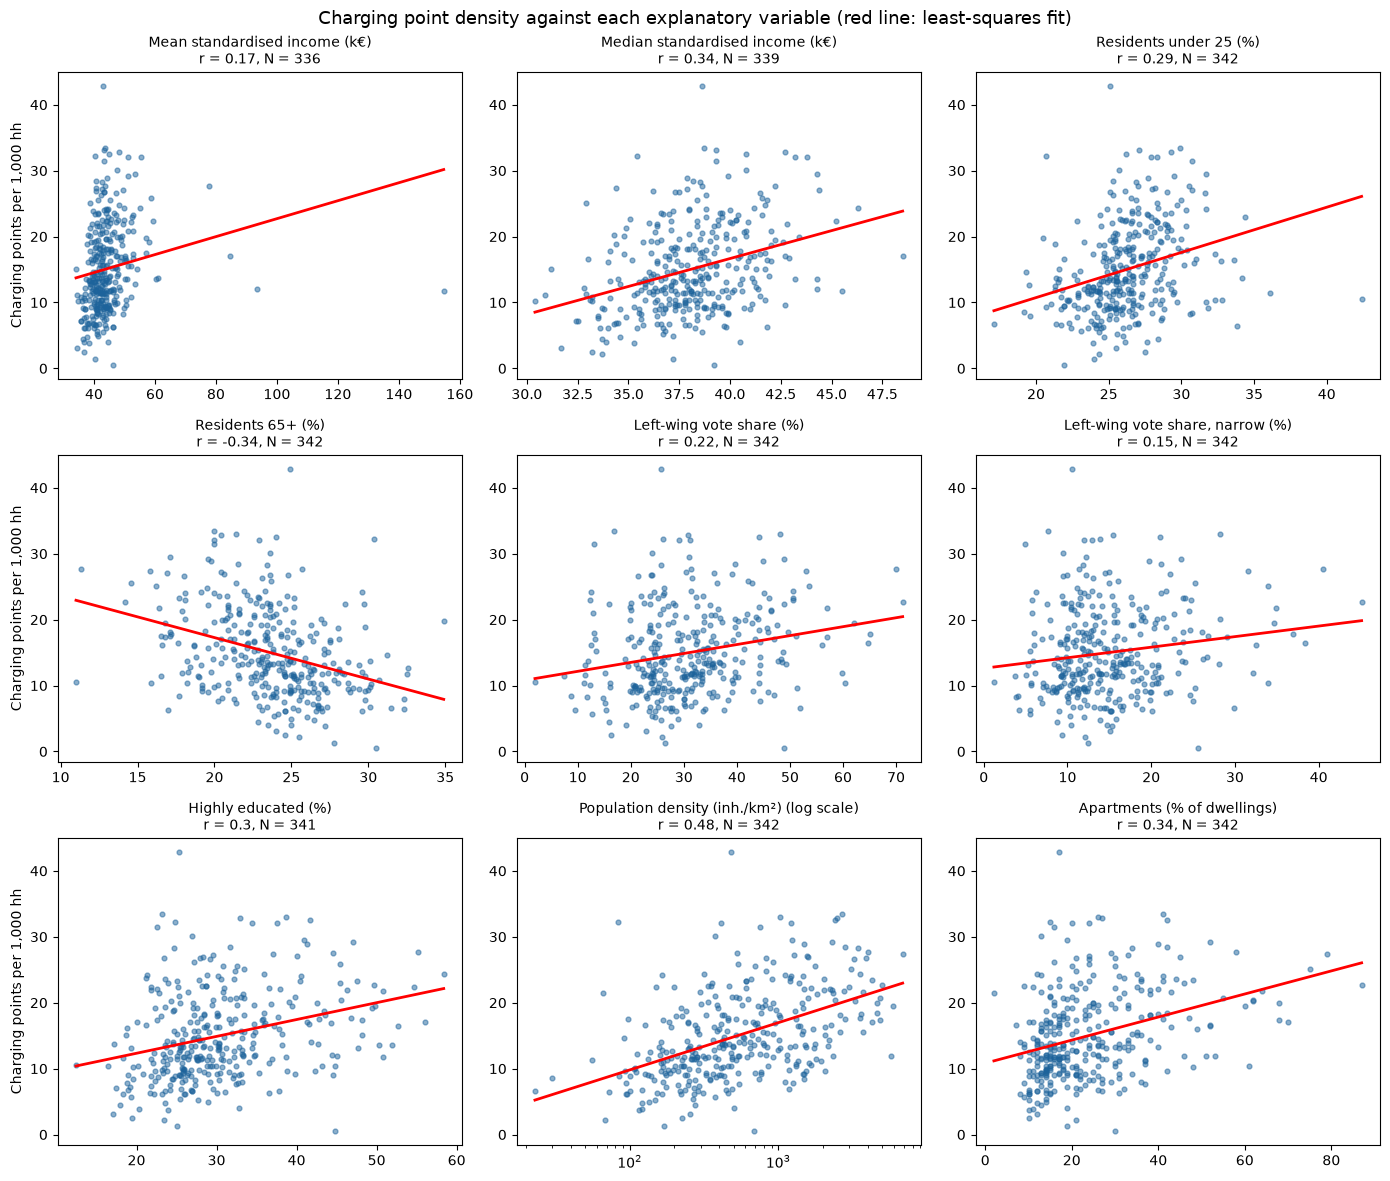

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.flatten()                # from a 3 x 3 grid to a list of 9 axes

for i in range(len(explanatory)):
    col = explanatory[i]
    ax = axes[i]

    # Only municipalities with a value for both variables
    pair = data[[col, target]].dropna()
    x = pair[col]
    y = pair[target]

    if col == "Population density (inh./km²)":
        x_fit = np.log(x)            # skewed variable: use log(x)
        ax.set_xscale("log")
        title = col + " (log scale)"
    else:
        x_fit = x
        title = col

    # Least-squares line y = a + b * x
    b, a = np.polyfit(x_fit, y, 1)
    r, p = stats.pearsonr(x_fit, y)

    x_line = np.linspace(x.min(), x.max(), 100)
    if col == "Population density (inh./km²)":
        y_line = a + b * np.log(x_line)
    else:
        y_line = a + b * x_line

    ax.scatter(x, y, s=12, alpha=0.5, color="#1d639b")
    ax.plot(x_line, y_line, color="red", linewidth=2)
    ax.set_title(title + "\nr = " + str(round(r, 2)) + ", N = " + str(len(pair)), fontsize=10)

    if i % 3 == 0:                   # y-label only in the left column
        ax.set_ylabel("Charging points per 1,000 hh")

fig.suptitle("Charging point density against each explanatory variable (red line: least-squares fit)", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES + "figure_scatter_all_factors.png", dpi=200)
plt.show()

## 4. Interpretation

> ** Still to do**